## Ejercicio hiperparametrización breast cancer de sklearn

1. Carga el dataset [breast_cancer de `sklearn`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
2. Prueba al menos 5 modelos diferentes de clasificación y aplica un GridSearchCV mediante Pipelines. Aplica también un RandomizedSearchCV.
3. Conclusiones. Guarda el modelo final en un archivo con pickle.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

In [2]:
%matplotlib inline
data = load_breast_cancer()
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [3]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [ ]:
print(data['DESCR'])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [5]:
df = pd.DataFrame(data['data'], columns=data['feature_names'])
df['target'] = data['target']
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [8]:
import pandas as pd
import numpy as np
from scipy.stats import randint, uniform

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Asumiendo que tu DataFrame se llama 'df'
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) 
#StratifiedKFold: Divide los datos en bloques (folds) manteniendo la misma proporción de clases (0 y 1 en tu target) en cada bloque que en el dataset original. Así evitas que, por azar, una partición quede desbalanceada.

In [16]:
cols_redundantes = [
    "mean radius", "mean perimeter", "mean area", "worst radius", "worst area",
    "perimeter error", "area error",
    "mean texture",
    "mean concave points", "mean concavity",
]

cols_sin_senal = [
    "mean fractal dimension",
    "texture error",
    "symmetry error",
    "smoothness error",
    "fractal dimension error",
]

# Prueba 1: quitar solo redundantes (20 variables)
X_train_red = X_train.drop(columns=cols_redundantes)
X_test_red = X_test.drop(columns=cols_redundantes)

# Prueba 2: quitar redundantes + sin señal (15 variables)
X_train_clean = X_train.drop(columns=cols_redundantes + cols_sin_senal)
X_test_clean = X_test.drop(columns=cols_redundantes + cols_sin_senal)

In [18]:
modelos_y_grids = {
    "LogisticRegression": {
        "modelo": LogisticRegression(max_iter=5000, random_state=42),
        "params": {
            "clf__C": [0.01, 0.1, 1, 10, 100],
            "clf__solver": ["lbfgs", "liblinear"],
        },
    },
    "SVC": {
        "modelo": SVC(random_state=42),
        "params": {
            "clf__C": [0.1, 1, 10],
            "clf__kernel": ["linear", "rbf"],
            "clf__gamma": ["scale", "auto"],
        },
    },
    "KNN": {
        "modelo": KNeighborsClassifier(),
        "params": {
            "clf__n_neighbors": [3, 5, 7, 11, 15],
            "clf__weights": ["uniform", "distance"],
            "clf__metric": ["euclidean", "manhattan"],
        },
    },
    "RandomForest": {
        "modelo": RandomForestClassifier(random_state=42),
        "params": {
            "clf__n_estimators": [100, 200],
            "clf__max_depth": [None, 5, 10],
            "clf__min_samples_split": [2, 5],
        },
    },
    "GradientBoosting": {
        "modelo": GradientBoostingClassifier(random_state=42),
        "params": {
            "clf__n_estimators": [100, 200],
            "clf__learning_rate": [0.05, 0.1, 0.2],
            "clf__max_depth": [2, 3, 5],
        },
    },
}

resultados = []
mejores_estimadores = {}

for nombre, config in modelos_y_grids.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", config["modelo"]),
    ])
    
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=config["params"],
        cv=cv,
        scoring="f1",  # También puedes usar "accuracy" o "roc_auc"
        n_jobs=-1,
    )
    grid.fit(X_train_clean, y_train)
    
    y_pred = grid.predict(X_test_clean)
    mejores_estimadores[nombre] = grid.best_estimator_
    
    resultados.append({
        "Modelo": nombre,
        "Mejor F1 (CV)": round(grid.best_score_, 4),
        "Accuracy (Test)": round(accuracy_score(y_test, y_pred), 4),
        "F1 (Test)": round(f1_score(y_test, y_pred), 4),
        "Mejores Hiperparámetros": grid.best_params_,
    })

df_resultados = pd.DataFrame(resultados).sort_values(by="Mejor F1 (CV)", ascending=False)
print(df_resultados[["Modelo", "Mejor F1 (CV)", "Accuracy (Test)", "F1 (Test)"]].to_string(index=False))

            Modelo  Mejor F1 (CV)  Accuracy (Test)  F1 (Test)
LogisticRegression         0.9809           0.9737     0.9793
               SVC         0.9792           0.9825     0.9861
  GradientBoosting         0.9703           0.9386     0.9517
               KNN         0.9573           0.9561     0.9660
      RandomForest         0.9546           0.9474     0.9589


In [19]:
from scipy.stats import loguniform

pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, random_state=42)),
])

param_distributions_lr = {
    "clf__C": loguniform(1e-3, 1e2),      # Prueba valores desde 0.001 hasta 100
    "clf__penalty": ["l1", "l2"],         # Regularización Lasso (L1) o Ridge (L2)
    "clf__solver": ["liblinear"],         # Compatible tanto con L1 como con L2
}

random_search_lr = RandomizedSearchCV(
    estimator=pipe_lr,
    param_distributions=param_distributions_lr,
    n_iter=40,
    cv=cv,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
)

random_search_lr.fit(X_train_clean, y_train)

y_pred_lr = random_search_lr.predict(X_test_clean)
print("Mejor F1 (CV):", round(random_search_lr.best_score_, 4))
print("Accuracy (Test):", round(accuracy_score(y_test, y_pred_lr), 4))
print("F1 (Test):", round(f1_score(y_test, y_pred_lr), 4))
print("Mejores parámetros:", random_search_lr.best_params_)

Mejor F1 (CV): 0.9809
Accuracy (Test): 0.9737
F1 (Test): 0.9793
Mejores parámetros: {'clf__C': np.float64(1.2357483710912178), 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}


c:\Users\laras\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [21]:
mejor_nombre = df_resultados.iloc[0]["Modelo"]
mejor_modelo = mejores_estimadores[mejor_nombre]

print(f"\nReporte de clasificación para el mejor modelo ({mejor_nombre}):")
print(classification_report(y_test, mejor_modelo.predict(X_test_clean)))


Reporte de clasificación para el mejor modelo (LogisticRegression):
              precision    recall  f1-score   support

           0       0.98      0.95      0.96        42
           1       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



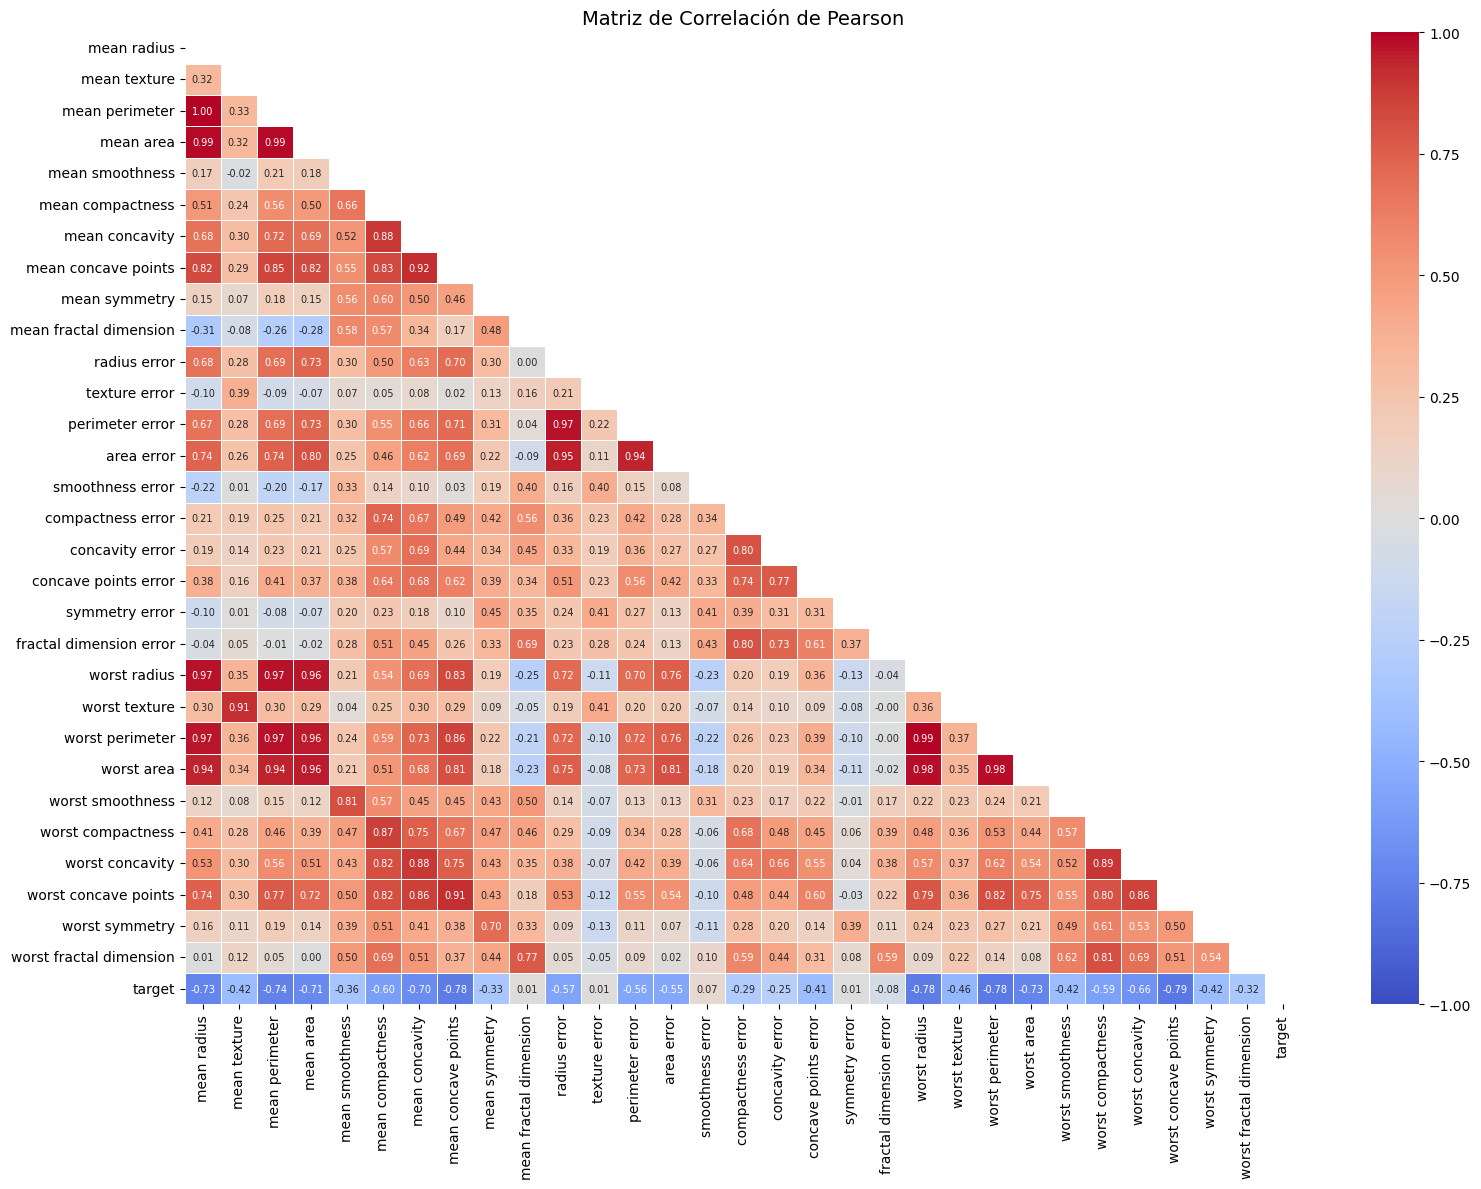

In [14]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Calcular matriz de correlación de Pearson
corr = df.corr(method="pearson")

# Máscara para ocultar el triángulo superior (es redundante)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    linewidths=0.5,
)
plt.title("Matriz de Correlación de Pearson", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
import pandas as pd

corr = df.corr(method="pearson").round(2)

with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 1000):
    print(corr)

                         mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimeter error  area error  smoothness error  compactness error  concavity error  concave points error  symmetry error  fractal dimension error  worst radius  worst texture  worst perimeter  worst area  worst smoothness  worst compactness  worst concavity  worst concave points  worst symmetry  worst fractal dimension  target
mean radius                     1.00          0.32            1.00       0.99             0.17              0.51            0.68                 0.82           0.15                   -0.31          0.68          -0.10             0.67        0.74             -0.22               0.21             0.19                  0.38           -0.10                    -0.04          0.97           0.30             0.97        0.94              0.12              